# 03 — Analyse exploratoire

À partir du fichier propre produit par `02_nettoyage.ipynb`. Les figures sont enregistrées
dans le dossier `figures/` pour être affichées dans le README.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

racine = Path.cwd()
while not (racine / "data" / "raw").exists() and racine != racine.parent:
    racine = racine.parent

chemin = racine / "data" / "processed" / "logements_paca.parquet"
if not chemin.exists():
    raise FileNotFoundError(f"Fichier introuvable : {chemin}\n→ Lance d'abord le notebook 02_nettoyage jusqu'au bout.")

logements = pd.read_parquet(chemin)

dossier_fig = racine / "figures"
dossier_fig.mkdir(exist_ok=True)

NOMS_DEP = {"04": "Alpes-de-Haute-Provence", "05": "Hautes-Alpes", "06": "Alpes-Maritimes",
            "13": "Bouches-du-Rhône", "83": "Var", "84": "Vaucluse"}
logements["code_departement"] = logements["code_departement"].astype(str).str.zfill(2)
logements["departement"] = logements["code_departement"].map(NOMS_DEP)

print(logements.shape)
logements["departement"].value_counts()

(434089, 15)


departement
Bouches-du-Rhône           131694
Alpes-Maritimes            122377
Var                        112617
Vaucluse                    36405
Hautes-Alpes                15876
Alpes-de-Haute-Provence     15120
Name: count, dtype: int64

## 1. Distribution des prix au m²

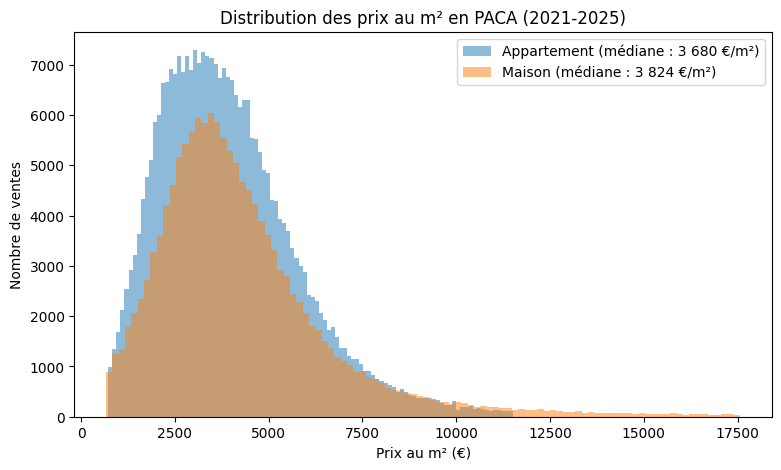

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
for type_local, couleur in [("Appartement", "tab:blue"), ("Maison", "tab:orange")]:
    s = logements.loc[logements["type_local"] == type_local, "prix_m2"]
    ax.hist(s, bins=100, alpha=0.5, color=couleur,
            label=f"{type_local} (médiane : {s.median():,.0f} €/m²)".replace(",", " "))
ax.set(title="Distribution des prix au m² en PACA (2021-2025)",
       xlabel="Prix au m² (€)", ylabel="Nombre de ventes")
ax.legend()
fig.savefig(dossier_fig / "distribution_prix_m2.png", dpi=150, bbox_inches="tight")
plt.show()

**Une distribution asymétrique.** Les prix au m² se concentrent entre 2 500 et 5 000 €, avec une médiane de 3 680 €/m² pour les appartements et de 3 824 €/m² pour les maisons. La distribution présente une **longue traîne à droite**, beaucoup plus marquée pour les maisons : il s'agit des villas haut de gamme du littoral, qui montent jusqu'à 17 500 €/m².

**Conséquence pour le modèle :** une cible aussi étirée est difficile à modéliser directement, car quelques ventes très chères pèsent énormément dans l'erreur. On prédira donc le **logarithme du prix**, qui rend la distribution beaucoup plus symétrique.

## 2. Carte des prix au m²

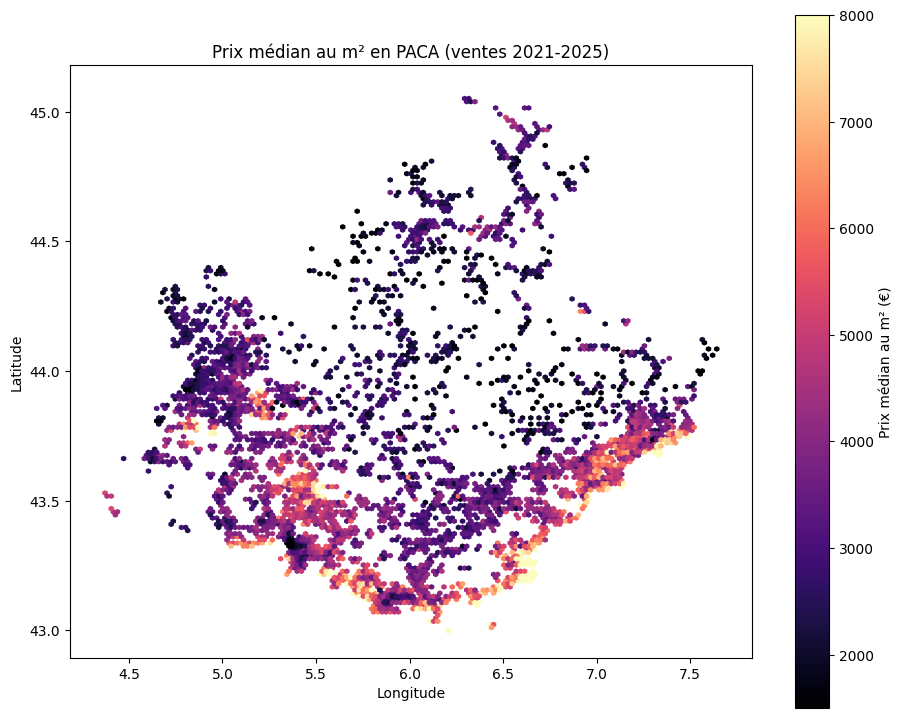

In [3]:
fig, ax = plt.subplots(figsize=(11, 9))
hb = ax.hexbin(
    logements["longitude"], logements["latitude"],
    C=logements["prix_m2"], reduce_C_function=np.median,  # prix médian dans chaque hexagone
    gridsize=150, mincnt=5,                                # au moins 5 ventes par hexagone
    cmap="magma", vmin=1500, vmax=8000,
)
fig.colorbar(hb, ax=ax, label="Prix médian au m² (€)")
ax.set_aspect(1 / np.cos(np.radians(43.8)))  # corrige la déformation due à la latitude
ax.set(title="Prix médian au m² en PACA (ventes 2021-2025)", xlabel="Longitude", ylabel="Latitude")
fig.savefig(dossier_fig / "carte_prix_m2.png", dpi=150, bbox_inches="tight")
plt.show()

**Le littoral avant tout.** La carte fait apparaître nettement la géographie des prix :

- **les zones les plus chères** (en jaune) suivent la côte : la Côte d'Azur de Cannes à Menton, la presqu'île de Saint-Tropez, ainsi que Cassis, Bandol et Sanary ;
- **à l'intérieur des terres**, deux zones se distinguent aussi : **Aix-en-Provence** et le **Luberon** (Gordes, Ménerbes), deux secteurs résidentiels très recherchés ;
- **l'arrière-pays** (Alpes-de-Haute-Provence, haut Var, haut pays niçois) est nettement moins cher, souvent autour de 2 000 €/m² ;
- dans les Alpes, quelques points plus clairs correspondent aux **stations de ski** ;
- **Marseille** est très contrastée : on voit une tache sombre au nord de la ville (quartiers nord) juste à côté de zones beaucoup plus chères au sud.

**Conséquence pour le modèle :** le prix dépend fortement de la localisation, et à une échelle très fine, bien plus fine que la commune ou le département. Les coordonnées GPS, la distance à la mer et le prix des ventes voisines seront des variables clés.

## 3. Évolution dans le temps

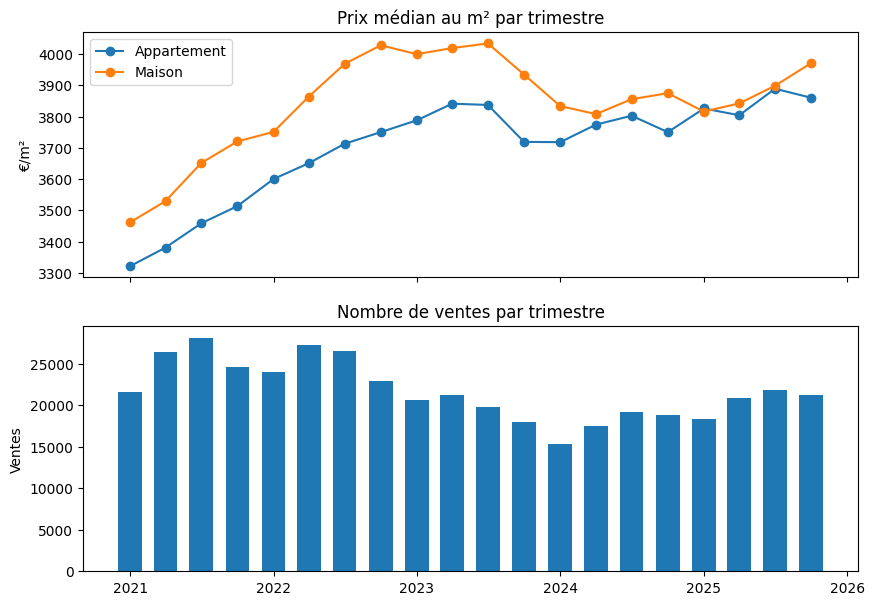

In [4]:
trimestre = logements["date_mutation"].dt.to_period("Q")
evolution = logements.groupby([trimestre, "type_local"])["prix_m2"].median().unstack()
volume = logements.groupby(trimestre).size()
evolution.index = evolution.index.to_timestamp()
volume.index = volume.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for colonne in evolution.columns:
    ax1.plot(evolution.index, evolution[colonne], marker="o", label=colonne)
ax1.set(title="Prix médian au m² par trimestre", ylabel="€/m²")
ax1.legend()
ax2.bar(volume.index, volume.values, width=60)
ax2.set(title="Nombre de ventes par trimestre", ylabel="Ventes")
fig.savefig(dossier_fig / "evolution_temporelle.png", dpi=150, bbox_inches="tight")
plt.show()

**Trois phases sur la période.**

1. **2021 – mi-2023 : forte hausse.** Le prix médian des appartements passe d'environ 3 300 à 3 840 €/m² (+16 %), celui des maisons de 3 460 à 4 030 €/m².
2. **Fin 2023 – 2024 : baisse.** Les prix reculent de 3 à 6 %, et surtout le **nombre de ventes s'effondre** : environ 28 000 par trimestre à l'été 2021, à peine plus de 15 000 début 2024. Cela correspond à la remontée rapide des taux d'intérêt, qui a réduit la capacité d'emprunt des acheteurs.
3. **2025 : reprise.** Le volume de ventes remonte vers 21 000 par trimestre et les prix repartent légèrement à la hausse.

Le dernier trimestre 2025 contient environ 21 000 ventes : les données de l'année sont donc complètes.

**Conséquence pour le modèle :** les prix dépendent du moment de la vente, la date sera donc une variable. Pour évaluer le modèle honnêtement, on fera un **découpage temporel** : entraînement sur 2021-2024 et test sur 2025. Cela simule la situation réelle, où l'on estime des ventes futures à partir du passé.

## 4. Prix par département

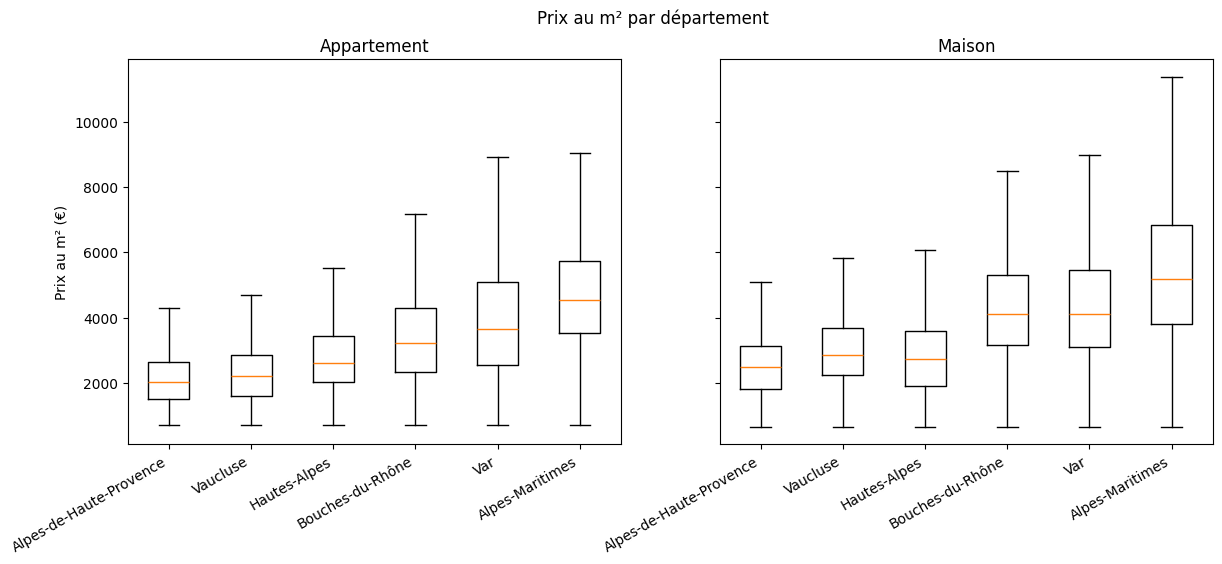

In [5]:
ordre = logements.groupby("departement")["prix_m2"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, type_local in zip(axes, ["Appartement", "Maison"]):
    sous = logements[logements["type_local"] == type_local]
    ax.boxplot([sous.loc[sous["departement"] == d, "prix_m2"] for d in ordre], showfliers=False)
    ax.set_xticks(range(1, len(ordre) + 1))
    ax.set_xticklabels(ordre, rotation=30, ha="right")
    ax.set_title(type_local)
axes[0].set_ylabel("Prix au m² (€)")
fig.suptitle("Prix au m² par département")
fig.savefig(dossier_fig / "prix_par_departement.png", dpi=150, bbox_inches="tight")
plt.show()

**Un fort gradient entre départements.** Du moins cher au plus cher : Alpes-de-Haute-Provence (environ 2 000 €/m² pour un appartement), Vaucluse, Hautes-Alpes, Bouches-du-Rhône, Var, puis Alpes-Maritimes (environ 4 500 €/m², et plus de 5 000 €/m² pour les maisons).

**Le cas des Hautes-Alpes.** Les appartements y sont plus chers que dans le Vaucluse, alors que le département est rural. C'est l'effet des **stations de ski** (Serre-Chevalier, Orcières, Vars…), où se concentrent les ventes d'appartements, souvent des résidences secondaires.

**Une forte variabilité interne.** À l'intérieur d'un même département, les écarts sont considérables : dans le Var, la moitié centrale des appartements se vend entre 2 500 et 5 100 €/m², du simple au double. **Le département seul ne suffit donc pas** à expliquer les prix : il faut une localisation plus précise.

## 5. Communes les plus et les moins chères

In [6]:
par_commune = logements.groupby("nom_commune").agg(
    nb_ventes=("prix_m2", "size"),
    prix_m2_median=("prix_m2", "median"),
)
# On ne garde que les communes avec assez de ventes pour que la médiane soit fiable
fiables = par_commune[par_commune["nb_ventes"] >= 100].sort_values("prix_m2_median")
print(f"{len(fiables)} communes avec au moins 100 ventes")

433 communes avec au moins 100 ventes


In [7]:
print("🔻 Les 10 moins chères")
fiables.head(10)

🔻 Les 10 moins chères


,nb_ventes,prix_m2_median
nom_commune,,
Tende,174,1414.717349
Veynes,238,1464.128205
Serres,108,1495.192308
Andon,128,1552.362708
Aiguilles,101,1666.666667
Seyne,233,1704.666667
Gréolières,207,1721.111111
Laragne-Montéglin,214,1764.194066
Puget-Théniers,113,1773.853211


In [8]:
print("🔺 Les 10 plus chères")
fiables.tail(10).iloc[::-1]

🔺 Les 10 plus chères


,nb_ventes,prix_m2_median
nom_commune,,
Ramatuelle,179,10434.782609
Saint-Jean-Cap-Ferrat,103,9827.586207
Saint-Tropez,587,9002.666667
Èze,259,7812.500000
Rayol-Canadel-sur-Mer,160,7534.173619
Cap-d'Ail,389,7508.474576
Villefranche-sur-Mer,791,7452.700000
Eygalières,142,7352.564103
Beaulieu-sur-Mer,540,7166.666667


**Les plus chères : le littoral de prestige.** Le haut du classement est occupé par des communes côtières très recherchées : Ramatuelle (10 400 €/m²), Saint-Jean-Cap-Ferrat, Saint-Tropez, Èze, Cap-d'Ail, Villefranche-sur-Mer, Beaulieu-sur-Mer ou Cassis. Une exception notable : **Eygalières**, village des Alpilles à l'intérieur des terres, qui doit sa place à son attractivité touristique et résidentielle plutôt qu'à la mer.

**Les moins chères : les villages de montagne et l'arrière-pays.** Tende, Veynes, Serres, Andon, Seyne, Puget-Théniers ou Digne-les-Bains se vendent autour de 1 400 à 1 800 €/m², soit **jusqu'à sept fois moins cher** que Ramatuelle.

Fait marquant : plusieurs des communes les moins chères (Tende, Andon, Gréolières, Puget-Théniers) se trouvent dans les **Alpes-Maritimes**, le département le plus cher. Cela confirme que l'opposition entre le littoral et l'arrière-pays compte plus que le découpage administratif.

## 6. Surface et prix

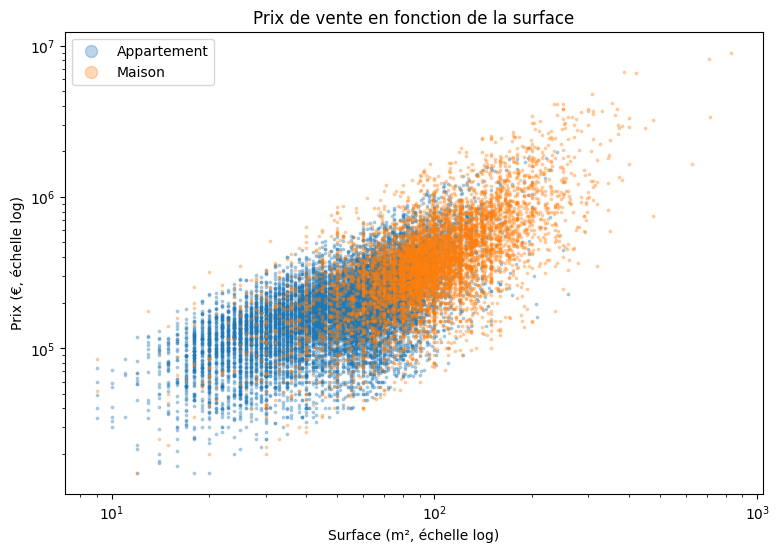

In [9]:
echantillon = logements.sample(min(20_000, len(logements)), random_state=42)  # 20 000 points suffisent pour voir la tendance

fig, ax = plt.subplots(figsize=(9, 6))
for type_local, couleur in [("Appartement", "tab:blue"), ("Maison", "tab:orange")]:
    s = echantillon[echantillon["type_local"] == type_local]
    ax.scatter(s["surface_reelle_bati"], s["valeur_fonciere"], s=3, alpha=0.3, color=couleur, label=type_local)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(title="Prix de vente en fonction de la surface", xlabel="Surface (m², échelle log)",
       ylabel="Prix (€, échelle log)")
ax.legend(markerscale=5)
fig.savefig(dossier_fig / "surface_vs_prix.png", dpi=150, bbox_inches="tight")
plt.show()

**Une relation quasi linéaire en échelle log.** En échelle logarithmique, le prix augmente de façon presque linéaire avec la surface : quand la surface double, le prix fait à peu près de même. C'est un argument supplémentaire pour modéliser le **logarithme du prix**.

**Mais une forte dispersion à surface égale.** Pour une même surface, le prix varie facilement d'un facteur 5 à 10. Par exemple, un appartement de 50 m² peut se vendre 60 000 € comme 500 000 €. Ce qui explique cet écart, c'est principalement **la localisation**, comme le montrent la carte et le classement des communes.

On remarque aussi que les maisons sont en moyenne plus grandes que les appartements, et que les très grandes surfaces sont presque toujours des maisons.

## Conclusions pour la modélisation

1. **La localisation est le facteur dominant**, et elle joue à une échelle très fine. Le modèle devra utiliser les coordonnées GPS, la distance à la mer et aux grandes villes, et le niveau de prix des ventes voisines.
2. **La surface est le second facteur**, avec une relation proche de la proportionnalité. On modélisera le **logarithme du prix**, ce qui gère aussi la longue traîne de la distribution.
3. **Le marché a évolué sur la période**, avec une hausse, une baisse puis une reprise. La date de vente sera une variable, et l'évaluation se fera avec un **découpage temporel** : entraînement sur 2021-2024, test sur 2025.
4. **Le périmètre du modèle** : des logements anciens (hors VEFA) et hors grand luxe, à cause du filtrage des valeurs extrêmes.